# 11. Swelling and squeezing of a gel

**Track:** core &nbsp;·&nbsp; **Prerequisites:** Chapters 3–5 and 10

A gel is a network of polymers, or of linked particles, filled with a solvent. Put a
dry contact lens or a piece of agar into water and it swells. Press a wet sponge, or
squeeze a gel between two plates, and the solvent comes out. Both processes are
slow, for the same reason: the solvent has to flow through the fine mesh of the
network, and the network resists the flow with a large friction.

In Chapter 10 the particles of a suspension were free. In a gel they are tied
together, so the network has an elastic free energy with two moduli: a bulk modulus
$K$ that resists a change of volume, and a shear modulus $G$ that resists a change of
shape. This chapter writes the two functions of a gel, derives the equation for the
displacement of the network, and solves it for two shapes: a sheet, which swells or
is squeezed in one direction, and a sphere.

The sphere has a history. Tanaka and Fillmore (1979) found that the swelling time
of a gel sphere is set by the collective diffusion coefficient of the network,
measured by light scattering. They neglected the shear modulus; Peters and Candau
(1986, 1988) and Li and Tanaka (1990) showed that it changes the answer. We shall
see that the swelling time of a sphere is set mainly by the *bulk* modulus. A trial
function with one parameter, a uniform dilation, shows why, and three parameters
give the exact rate to four digits.

In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np
import sympy as sp
from matplotlib.patches import FancyArrowPatch, Rectangle
from scipy.linalg import eigh, expm

try:
    import onsager as on
except ImportError:          # running from a clone without `pip install -e .`
    import sys
    sys.path.insert(0, "../..")
    import onsager as on

on.use_style()

## 11.1 The two functions of a gel

The network moves with the displacement $\mathbf u(\mathbf r,t)$, measured from the
state in which the gel was made, and with the velocity $\mathbf v_p = \dot{\mathbf u}$. The
solvent moves with the velocity $\mathbf v_s$. The network occupies the volume
fraction $\phi$.

*Free energy.* For small deformations,

$$ A = \int\Big[\tfrac12K\,(\nabla\cdot\mathbf u)^2 + G\,\tilde\varepsilon_{ij}\tilde\varepsilon_{ij} - \Pi_0\,\nabla\cdot\mathbf u\Big]\,dV , \tag{11.1} $$

where $\tilde\varepsilon_{ij} = \tfrac12(\partial_iu_j + \partial_ju_i) - \tfrac13\delta_{ij}\nabla\cdot\mathbf u$ is the
shear part of the strain. $K$ is the osmotic bulk modulus of the network and $G$ its
shear modulus. The last term drives the swelling: $\Pi_0$ is the *swelling pressure*,
the osmotic pressure that the network feels in the solvent, at the state in which it
was made. A free gel in equilibrium swells uniformly by $\nabla\cdot\mathbf u = \Pi_0/K$. A
negative $\Pi_0$ describes a gel that shrinks. The stress of the network is
$\sigma_{ij} = \partial f/\partial(\partial_ju_i)$, with $f$ the integrand of Eq. (11.1):

$$ \sigma_{ij} = \big(K\,\nabla\cdot\mathbf u - \Pi_0\big)\,\delta_{ij} + 2G\,\tilde\varepsilon_{ij} . \tag{11.2} $$

*Constraint.* Network and solvent together cannot be compressed (Chapter 10):

$$ \nabla\cdot\big[\phi\,\mathbf v_p + (1 - \phi)\,\mathbf v_s\big] = 0 . \tag{11.3} $$

*Dissipation.* As in Chapter 10, the solvent rubs against the network:

$$ \Phi = \frac12\int\xi\,(\mathbf v_p - \mathbf v_s)^2\,dV , \tag{11.4} $$

with $\xi = \eta/\kappa$ for a network of permeability $\kappa$ (Section 4.5).

*Minimise.* The rate of change of the free energy is
$\dot A = -\int(\nabla\cdot\boldsymbol\sigma)\cdot\dot{\mathbf u}\,dV$ plus a surface term, and the
constraint is imposed with the pressure $p$ as a Lagrange multiplier (Section 3.4).
Minimising over $\mathbf v_p$ and $\mathbf v_s$ gives two equations (the cell below does the
algebra in one dimension):

$$ \nabla\cdot\boldsymbol\sigma = \nabla p , \qquad \xi\,(\mathbf v_s - \mathbf v_p) = -(1 - \phi)\,\nabla p . \tag{11.5} $$

The first is the force balance of the gel as a whole: the elastic stress of the
network is balanced by the pressure of the solvent. The second is Darcy's law for
the flow of solvent through the network.

When the volume flux $\phi\mathbf v_p + (1 - \phi)\mathbf v_s$ vanishes, which is the case for
the sheet and the sphere of this chapter (it has zero divergence and is zero at the
centre or at a wall), the two equations combine into one equation for the network:

$$ f\,\frac{\partial\mathbf u}{\partial t} = \nabla\cdot\boldsymbol\sigma , \qquad f = \frac{\xi}{(1 - \phi)^2} . \tag{11.6} $$

This is the equation of Tanaka, Hocker and Benedek (1973), used by Tanaka and
Fillmore (1979). For a displacement without rotation, $\nabla\times\mathbf u = 0$, the force
is $\nabla\cdot\boldsymbol\sigma = M\,\nabla(\nabla\cdot\mathbf u)$, with the *longitudinal modulus*
$M = K + \tfrac43G$, and Eq. (11.6) becomes a diffusion equation:

$$ \frac{\partial\mathbf u}{\partial t} = D\,\nabla(\nabla\cdot\mathbf u) , \qquad D = \frac{M}{f} = \frac{K + \tfrac43G}{f} . \tag{11.7} $$

$D$ is the *collective diffusion coefficient* of the gel, the quantity measured by
light scattering. It plays the role of $D_c$ in Chapter 10. The dissipation is then
simply $\Phi = \tfrac12\int f\,\dot{\mathbf u}^2\,dV$.

*Boundary conditions.* At a surface in contact with the outside solvent, the
solvent pressure equals the outside pressure, $p = 0$, and the total force on the
surface vanishes, so the network stress is zero there: $\boldsymbol\sigma\cdot\mathbf n = 0$. This
condition does not have to be imposed by hand: it is the natural boundary condition
of the minimisation. At a rigid, impermeable wall the network is held, $\mathbf u = 0$.

In [2]:
vp, vs, phi, xi, dsig, dp = sp.symbols("v_p v_s phi xi dsigma dp")
# Rayleighian density in one dimension.  dsig = d(sigma)/dz; dp = dp/dz.
# Adot gives -dsig * v_p after an integration by parts; the constraint term gives +dp * (volume flux).
R = xi * (vp - vs) ** 2 / 2 - dsig * vp + dp * (phi * vp + (1 - phi) * vs)
eqs = [sp.diff(R, vp), sp.diff(R, vs)]
general = sp.solve(eqs, [vp, dsig], dict=True)[0]
print("force balance:       dsigma/dz =", sp.simplify(general[dsig]))
print("Darcy's law:         v_p - v_s =", sp.factor(sp.solve(eqs[1], vp)[0] - vs))
zero_flux = sp.solve(eqs + [phi * vp + (1 - phi) * vs], [vp, vs, dp], dict=True)[0]
print("with no volume flux: v_p       =", sp.factor(zero_flux[vp]), "  i.e. f v_p = dsigma/dz, f = xi/(1-phi)^2")

force balance:       dsigma/dz = dp
Darcy's law:         v_p - v_s = -dp*(phi - 1)/xi
with no volume flux: v_p       = dsigma*(phi - 1)**2/xi   i.e. f v_p = dsigma/dz, f = xi/(1-phi)^2


## 11.2 A sheet: swelling on a substrate, and squeezing under a piston

A gel sheet of thickness $h$ is bonded to a rigid, impermeable substrate at $z = 0$;
its top face $z = h$ is in contact with the solvent. The sheet cannot expand
sideways, so it swells only in thickness: $\mathbf u = u(z,t)\,\hat{\mathbf z}$. Then
$\nabla\cdot\mathbf u = \partial u/\partial z$, the shear part of the strain is fixed by it, and Eq. (11.7)
reads $\partial u/\partial t = D\,\partial^2u/\partial z^2$. The stress-free top gives
$M\,\partial u/\partial z = \Pi_0$ at $z = h$. The final state is a uniform strain $\Pi_0/M$.

*Units.* We measure lengths in units of $h$ (or of the radius $a$ of the sphere
below), displacements in units of their final value at the surface, and times in
units of $fh^2/K$. Then $\partial u/\partial t = (M/K)\,\partial^2u/\partial z^2$, and the solution starting from
$u = 0$ is (`on.gel_sheet_series`)

$$ u(z,t) = z - \sum_{k=0}^\infty\frac{8\,(-1)^k}{m^2\pi^2}\,\sin\frac{m\pi z}{2}\,e^{-(M/K)m^2\pi^2t/4} , \qquad m = 2k + 1 . \tag{11.8} $$

The thickness grows as $u(1,t)$; it approaches its final value with the slowest time

$$ \tau_{\rm sheet} = \frac{4h^2}{\pi^2D} . \tag{11.9} $$

*Squeezing.* Now put a porous piston on the top face and press it with the pressure
$P$. At the first instant the network cannot move: the mixture is incompressible and
no solvent has yet left, so the whole load is carried by the solvent, $p = P$. As the
solvent flows out through the piston, the load passes to the network. Force balance,
Eq. (11.5), says that $p - \sigma_{zz} = P$ everywhere, so

$$ \frac{p(z,t)}{P} = 1 - \frac{\partial u}{\partial z} , \tag{11.10} $$

with the same function $u$ as in Eq. (11.8), the sheet now getting thinner by $Ph/M$
in the end. Swelling and squeezing are the same process, run with opposite signs.
The squeezing of a porous medium under a load is the problem of *consolidation*, in
soil mechanics after Terzaghi; the general linear theory of a solid filled with a
liquid is Biot's (1941), of which the gel of this chapter is a special case.

In [3]:
z = np.linspace(0, 1, 401)
ratio = 0.6                                 # G/K, a typical value for a hydrogel
M = 1 + 4 * ratio / 3                       # M/K
times_sheet = np.array([0.003, 0.02, 0.08, 0.2, 0.5]) / M
profiles = [np.gradient(on.gel_sheet_series(z, t, ratio), z) for t in times_sheet]
print("sheet, G/K = 0.6:  thickness change u(1)/u_final at t M/K = 0.003, 0.02, 0.08, 0.2, 0.5:",
      np.round([on.gel_sheet_series(np.array([1.0]), t, ratio)[0] for t in times_sheet], 4))
D = 1e-11                                   # m^2/s, collective diffusion coefficient of a dilute hydrogel
print("\n thickness    slowest time 4h^2/(pi^2 D),  D = 1e-11 m^2/s")
for h in (10e-6, 100e-6, 1e-3, 1e-2):
    tau = 4 * h * h / (math.pi**2 * D)
    print(f"   {h * 1e3:6.2f} mm    {tau:10.3g} s  = {tau / 3600:8.3g} h")

sheet, G/K = 0.6:  thickness change u(1)/u_final at t M/K = 0.003, 0.02, 0.08, 0.2, 0.5: [0.0618 0.1596 0.3192 0.5041 0.764 ]

 thickness    slowest time 4h^2/(pi^2 D),  D = 1e-11 m^2/s
     0.01 mm          4.05 s  =  0.00113 h
     0.10 mm           405 s  =    0.113 h
     1.00 mm      4.05e+04 s  =     11.3 h
    10.00 mm      4.05e+06 s  = 1.13e+03 h


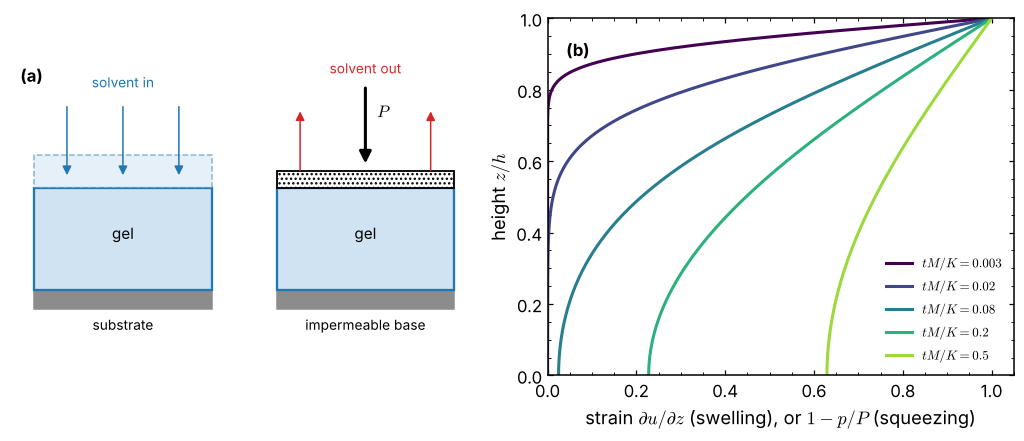

In [4]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9.2, 3.9))
ax1.set_xlim(0, 10); ax1.set_ylim(0, 6); ax1.set_aspect("equal"); ax1.axis("off")
# swelling on a substrate
ax1.add_patch(Rectangle((0.5, 0.6), 3.8, 0.4, color="0.55"))
ax1.add_patch(Rectangle((0.5, 1.0), 3.8, 2.2, facecolor="#cfe3f3", edgecolor="C0", lw=1.5))
ax1.add_patch(Rectangle((0.5, 3.2), 3.8, 0.7, facecolor="#cfe3f3", edgecolor="C0", lw=1.0, ls="--", alpha=0.5))
for x in (1.2, 2.4, 3.6):
    ax1.add_patch(FancyArrowPatch((x, 5.0), (x, 3.4), arrowstyle="-|>", mutation_scale=12, color="C0"))
ax1.text(2.4, 5.35, "solvent in", ha="center", fontsize=9, color="C0")
ax1.text(2.4, 0.15, "substrate", ha="center", fontsize=9)
ax1.text(2.4, 2.1, "gel", ha="center", fontsize=10)
# squeezing under a porous piston
ax1.add_patch(Rectangle((5.7, 0.6), 3.8, 0.4, color="0.55"))
ax1.add_patch(Rectangle((5.7, 1.0), 3.8, 2.2, facecolor="#cfe3f3", edgecolor="C0", lw=1.5))
ax1.add_patch(Rectangle((5.7, 3.2), 3.8, 0.35, facecolor="white", edgecolor="k", hatch="....", lw=1.2))
ax1.add_patch(FancyArrowPatch((7.6, 5.4), (7.6, 3.65), arrowstyle="-|>", mutation_scale=16, color="k", lw=2))
ax1.text(7.85, 4.7, "$P$", fontsize=11)
for x in (6.2, 9.0):
    ax1.add_patch(FancyArrowPatch((x, 3.5), (x, 4.9), arrowstyle="-|>", mutation_scale=12, color="C3"))
ax1.text(7.6, 5.65, "solvent out", ha="center", fontsize=9, color="C3")
ax1.text(7.6, 0.15, "impermeable base", ha="center", fontsize=9)
ax1.text(7.6, 2.1, "gel", ha="center", fontsize=10)
on.panel_label(ax1, "(a)", x=0.02, y=0.97)

for t, p, color in zip(times_sheet, profiles, plt.cm.viridis(np.linspace(0, 0.85, len(times_sheet)))):
    ax2.plot(p, z, color=color, lw=2, label=f"$tM/K = {t * M:g}$")
ax2.set_xlabel(r"strain $\partial u/\partial z$ (swelling), or $1 - p/P$ (squeezing)")
ax2.set_ylabel("height $z/h$"); ax2.set_xlim(0, 1.05); ax2.set_ylim(0, 1)
ax2.legend(loc="lower right", fontsize=8.5); on.panel_label(ax2, "(b)", x=0.04, y=0.94)
plt.show()

**Figure 11.1.** **(a)** A gel sheet swelling on a substrate (left), and squeezed by
a porous piston on an impermeable base (right). **(b)** Profiles of the strain of a
swelling sheet, in units of its final value, from the exact solution (11.8). The
swelling enters from the top, as in the diffusion problem of Chapter 5. For the
squeezed sheet the same curves give $1 - p/P$: the solvent pressure, equal to the
load at first, falls first near the piston.

The swelling time grows as the square of the thickness: a film of 10 µm swells in
seconds, a sheet of 1 mm in about half a day, and a slab of 1 cm in a month and a
half, for a typical hydrogel. This is why gel actuators, which respond to a change
of solvent by swelling, must be thin to be fast.

## 11.3 A sphere: Tanaka and Fillmore, and the shear modulus

A free gel sphere of radius $a$ swells by a radial displacement $u(r,t)$. Its
divergence is $\theta = \partial_ru + 2u/r$, Eq. (11.7) becomes

$$ \frac{\partial u}{\partial t} = D\,\frac{\partial\theta}{\partial r} , \qquad \theta = \frac{1}{r^2}\frac{\partial(r^2u)}{\partial r} , \tag{11.11} $$

and the condition of a stress-free surface, $\sigma_{rr} = 0$ at $r = a$, reads, from
Eq. (11.2),

$$ M\,\theta - \frac{4G}{a}\,u = \Pi_0 \qquad \text{at } r = a . \tag{11.12} $$

The final state is a uniform dilation, $u = (\Pi_0/3K)\,r$. The displacement relaxes to
it through modes $j_1(\alpha_nr/a)$, where $j_1$ is a spherical Bessel function. They decay
at the rates $M\alpha_n^2/fa^2$, and Eq. (11.12) fixes the numbers $\alpha_n$ (Exercise 3):

$$ \frac{G}{M} = \frac{\alpha^2}{4 - 4\alpha\cot\alpha} . \tag{11.13} $$

The series is in `on.gel_sphere_series`.

*Tanaka and Fillmore* solved the problem with the shear modulus neglected. Then
$\alpha_n = n\pi$, and the volume of the sphere approaches its final value as

$$ \frac{V(t) - V(0)}{V(\infty) - V(0)} = 1 - \sum_{n=1}^\infty\frac{6}{n^2\pi^2}\,e^{-n^2t/\tau} , \qquad \tau = \frac{a^2}{\pi^2D} . \tag{11.14} $$

They used it to measure $D$ from the swelling of polyacrylamide spheres, and found
it close to the value from light scattering. But in real gels $G$ is of the same order
as $K$. With $G \ne 0$ the slowest rate is $\lambda_1 = M\alpha_1^2/fa^2$, which is *not* $\pi^2D/a^2$.

*The approximation method.* The Rayleighian is a function of the displacement only,

$$ R = \frac12\int f\,\dot u^2\,dV + \dot A , \tag{11.15} $$

and we can try the simplest family: the deviation from the final state is a uniform
dilation, $u - u_\infty = c(t)\,r$. It has no shear, so $A = \tfrac12K(3c)^2V$ with $V$ the
volume of the sphere, and the friction is $\Phi = \tfrac12f\dot c^2\int r^2\,dV = \tfrac12f\dot c^2\,\tfrac35a^2V$.
Minimising over $\dot c$ gives

$$ \frac{3}{5}\,f a^2\,\dot c = -9K\,c \quad\Longrightarrow\quad \lambda_{\rm trial} = \frac{15K}{fa^2} . \tag{11.16} $$

The result does not depend on $G$ at all, and it has $K$, not $M$. The cell below
adds more terms, $u - u_\infty = c_1r + c_2r^3 + c_3r^5 + \ldots$, and compares the slowest
rates with the exact $\lambda_1$ for a range of $G/K$.

In [5]:
r, a, K_, f_ = sp.symbols("r a K f", positive=True)
c, cdot = sp.symbols("c cdot", real=True)
V = sp.Rational(4, 3) * sp.pi * a**3
A_trial = sp.Rational(1, 2) * K_ * (3 * c) ** 2 * V                         # uniform dilation: no shear
Phi_trial = sp.Rational(1, 2) * f_ * cdot**2 * sp.integrate(r**2 * 4 * sp.pi * r**2, (r, 0, a))
R_trial = Phi_trial + sp.diff(A_trial, c) * cdot
rate = -sp.solve(sp.diff(R_trial, cdot), cdot)[0] / c
print("one-term trial, uniform dilation:  rate =", sp.simplify(rate))

def ritz_matrices(n, g):
    """Stiffness and friction matrices for u - u_final = sum c_k r^(2k-1), units a, K, f a^2/K."""
    i = np.arange(1, n + 1)[:, None]
    j = i.T
    friction = 1.0 / (2 * i + 2 * j + 1)
    stiffness = ((2 * i + 1) * (2 * j + 1) + (4 / 3) * g * (2 * i - 2) * (2 * j - 2)) / (2 * i + 2 * j - 1)
    return stiffness, friction

def ritz_rates(n, g):
    return eigh(*ritz_matrices(n, g), eigvals_only=True)

def ritz_swelling(n, g, t):
    """Fraction of the swelling done, u(a, t)/u_final(a), from the n-term trial."""
    stiffness, friction = ritz_matrices(n, g)
    c0 = np.zeros(n); c0[0] = -1.0                               # starts from u = 0
    step = np.linalg.solve(friction, -stiffness)
    return np.array([1 + np.sum(expm(step * s) @ c0) for s in np.atleast_1d(t)])

def exact_rate(g):
    return (1 + 4 * g / 3) * on.gel_sphere_roots(g, 1)[0] ** 2

print("\n slowest rate in units of K/(f a^2)")
print("   G/K    exact     1 term    2 terms    3 terms    Tanaka-Fillmore with D = M/f")
for g in (0.0, 0.3, 0.6, 1.0, 3.0, 10.0, 100.0):
    print(f"  {g:5.1f}  {exact_rate(g):8.4f}  {ritz_rates(1, g)[0]:8.4f}  {ritz_rates(2, g)[0]:9.4f}"
          f"  {ritz_rates(3, g)[0]:9.4f}   {math.pi**2 * (1 + 4 * g / 3):9.3f}")

one-term trial, uniform dilation:  rate = 15*K/(a**2*f)

 slowest rate in units of K/(f a^2)
   G/K    exact     1 term    2 terms    3 terms    Tanaka-Fillmore with D = M/f
    0.0    9.8696   15.0000     9.9412     9.8699       9.870
    0.3   11.0719   15.0000    11.1092    11.0720      13.817
    0.6   11.8282   15.0000    11.8495    11.8282      17.765
    1.0   12.4810   15.0000    12.4924    12.4810      23.029
    3.0   13.7646   15.0000    13.7661    13.7646      49.348
   10.0   14.5575   15.0000    14.5576    14.5575     141.464
  100.0   14.9522   15.0000    14.9522    14.9522    1325.817


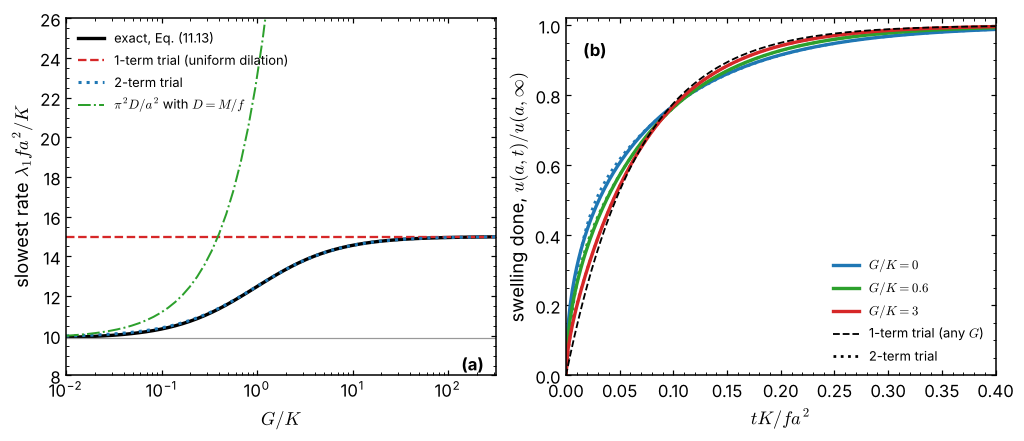

In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9.2, 3.9))
gs = np.logspace(-2, 2.5, 60)
ax1.semilogx(gs, [exact_rate(g) for g in gs], "k", lw=2.2, label=r"exact, Eq. (11.13)")
ax1.semilogx(gs, [ritz_rates(1, g)[0] for g in gs], "C3--", lw=1.5, label="1-term trial (uniform dilation)")
ax1.semilogx(gs, [ritz_rates(2, g)[0] for g in gs], "C0:", lw=2, label="2-term trial")
ax1.semilogx(gs, [math.pi**2 * (1 + 4 * g / 3) for g in gs], "C2-.", lw=1.3, label=r"$\pi^2D/a^2$ with $D = M/f$")
ax1.axhline(math.pi**2, color="0.6", lw=0.8)
ax1.set_xlabel(r"$G/K$"); ax1.set_ylabel(r"slowest rate $\lambda_1 fa^2/K$"); ax1.set_ylim(8, 26); ax1.set_xlim(1e-2, 10**2.5)
ax1.legend(loc="upper left", fontsize=8.5); on.panel_label(ax1, "(a)", x=0.92, y=0.06)

t = np.linspace(0, 0.4, 201)
for g, color in zip((0.0, 0.6, 3.0), ("C0", "C2", "C3")):
    swelling = on.gel_sphere_series(np.array([1.0]), t, g)[:, 0]
    ax2.plot(t, swelling, color=color, lw=2.2, label=f"$G/K = {g:g}$")
    ax2.plot(t, ritz_swelling(2, g, t), ":", color=color, lw=1.8)
ax2.plot(t, 1 - np.exp(-15 * t), "k--", lw=1.2, label="1-term trial (any $G$)")
ax2.plot([], [], "k:", lw=1.8, label="2-term trial")
ax2.set_xlabel(r"$tK/fa^2$"); ax2.set_ylabel(r"swelling done, $u(a,t)/u(a,\infty)$")
ax2.set_xlim(0, 0.4); ax2.set_ylim(0, 1.02)
ax2.legend(loc="lower right", fontsize=8.5); on.panel_label(ax2, "(b)", x=0.04, y=0.94)
plt.show()

**Figure 11.2.** A swelling gel sphere. **(a)** The slowest relaxation rate against the
ratio of the moduli: exact (full line), from trial functions with one and two terms,
and Tanaka and Fillmore's formula with the collective diffusion coefficient
$D = M/f$ (dash-dotted). **(b)** The swelling against time: exact (full lines),
the 2-term trial (dotted) and the 1-term trial (dashed), which is the same for all $G/K$.

Three things stand out.

* *The rate is set by $K$.* The exact rate rises only from $\pi^2K/fa^2$ to $15K/fa^2$ as
  the shear modulus goes from zero to infinity. The estimate $\pi^2D/a^2$ with the
  light-scattering coefficient $D = (K + \tfrac43G)/f$ grows without bound; at $G/K = 0.6$
  it is already 50 % too fast. This agrees with the conclusion of Man and Doi (2021)
  for a disk: the swelling time is set mainly by the friction and the bulk modulus.
* *The one-term trial explains why.* A shear modulus makes it expensive for the
  sphere to swell unevenly, so a stiff network swells nearly uniformly. A uniform
  dilation has no shear, so its rate cannot depend on $G$. For $G \gg K$ it becomes
  exact.
* *The trial rates are bounds.* Every trial rate lies above the exact one, and
  adding terms brings it down: two terms are within 0.8 %, three within 0.003 %.
  This is the minimum property of Chapter 1 at work: the slowest rate is the
  minimum over all displacements of the ratio of the stored energy to the
  friction, and a trial can only give a larger ratio (Doi and Yamaue, 2005).

## 11.4 Checks

The finite-element function `on.gel_fe` minimises a discretised Rayleighian, as in
Section 4.6, with piecewise-linear displacements. Each element contributes to a
stiffness matrix (from $A$) and a friction matrix (from $\Phi$), and the motion is then
found exactly in time. It is an independent check of both series. The cell below
compares them, measures how fast the trial functions converge, and computes the
stresses inside a swelling sphere.

In [7]:
check_times = np.array([0.002, 0.01, 0.05, 0.2])
errors = {}
for geometry, series in (("sheet", on.gel_sheet_series), ("sphere", on.gel_sphere_series)):
    for n_el in (50, 100, 200, 400):
        x, u = on.gel_fe(n_el, ratio, check_times, geometry)
        errors[geometry, n_el] = max(np.max(np.abs(u[k] - series(x, check_times[k], ratio))) for k in range(len(check_times)))
    print(f"{geometry:6s}: largest difference from the series, 50/100/200/400 elements:",
          "  ".join(f"{errors[geometry, n]:.1e}" for n in (50, 100, 200, 400)))

t_fine = np.concatenate((np.linspace(0.001, 0.05, 50), np.linspace(0.06, 0.6, 55)))
exact_curves = {g: on.gel_sphere_series(np.array([1.0]), t_fine, g)[:, 0] for g in (0.0, 0.6, 3.0)}
print("\nlargest error of the swelling curve u(a,t)/u(a,inf) from the n-term trial")
for g, curve in exact_curves.items():
    print(f"  G/K = {g:3.1f}: " + "  ".join(f"n = {n}: {np.max(np.abs(ritz_swelling(n, g, t_fine) - curve)):.1e}" for n in (1, 2, 3, 4, 6)))

def sphere_stresses(g, t, n_el=1200):
    """Total radial and hoop stresses, sigma - p, in units of the swelling pressure Pi0 = 3K.

    The network stress (11.2) is computed from the finite-element displacement; the solvent
    pressure follows from the force balance dp/dr = d(sigma_rr)/dr + 2(sigma_rr - sigma_tt)/r
    with p = 0 at the surface.
    """
    x, u = on.gel_fe(n_el, g, [t])
    u = u[0]
    xm = 0.5 * (x[1:] + x[:-1]); um = 0.5 * (u[1:] + u[:-1]); du = np.diff(u) / np.diff(x)
    dil = du + 2 * um / xm
    s_rr = dil - 3 + 2 * g * (du - dil / 3)                   # network stress, units K
    s_tt = dil - 3 + 2 * g * (um / xm - dil / 3)
    dpdr = np.gradient(s_rr, xm) + 2 * (s_rr - s_tt) / xm
    p = -np.concatenate((np.cumsum((0.5 * (dpdr[1:] + dpdr[:-1]) * np.diff(xm))[::-1])[::-1], [0.0]))
    p += -dpdr[-1] * (1 - xm[-1])                              # p = 0 at r = 1, half a cell beyond the last midpoint
    return xm, (s_rr - p) / 3, (s_tt - p) / 3

def surface_hoop_stress(g, times, n_el=2000):
    """Hoop stress at the surface / Pi0, for an array of times.  There p = 0, so the network
    stress (11.2) is the total stress."""
    x, u = on.gel_fe(n_el, g, times)
    du = (u[:, -1] - u[:, -2]) / (x[-1] - x[-2])
    dil = du + 2 * u[:, -1]
    return (dil - 3 + 2 * g * (u[:, -1] - dil / 3)) / 3

print("\nhoop stress at the surface / Pi0, against -2G/M at the first instant")
for g in (0.3, 0.6, 3.0):
    values = surface_hoop_stress(g, np.array([1e-4, 1e-3, 1e-2, 0.1]))
    print(f"  G/K = {g}:  t = 1e-4, 1e-3, 1e-2, 0.1: " + ", ".join(f"{v:+.3f}" for v in values)
          + f";   -2G/M = {-2 * g / (1 + 4 * g / 3):+.3f}")

sheet : largest difference from the series, 50/100/200/400 elements: 1.9e-04  4.7e-05  1.2e-05  3.0e-06


sphere: largest difference from the series, 50/100/200/400 elements: 3.3e-04  8.1e-05  2.0e-05  5.1e-06



largest error of the swelling curve u(a,t)/u(a,inf) from the n-term trial
  G/K = 0.0: n = 1: 1.7e-01  n = 2: 6.8e-02  n = 3: 3.3e-02  n = 4: 7.7e-03  n = 6: 3.3e-03
  G/K = 0.6: n = 1: 1.2e-01  n = 2: 4.1e-02  n = 3: 1.4e-02  n = 4: 4.1e-03  n = 6: 4.2e-04
  G/K = 3.0: n = 1: 5.9e-02  n = 2: 1.5e-02  n = 3: 2.4e-03  n = 4: 1.2e-03  n = 6: 7.6e-05

hoop stress at the surface / Pi0, against -2G/M at the first instant


  G/K = 0.3:  t = 1e-4, 1e-3, 1e-2, 0.1: -0.423, -0.392, -0.309, -0.100;   -2G/M = -0.429


  G/K = 0.6:  t = 1e-4, 1e-3, 1e-2, 0.1: -0.653, -0.614, -0.494, -0.157;   -2G/M = -0.667


  G/K = 3.0:  t = 1e-4, 1e-3, 1e-2, 0.1: -1.180, -1.137, -0.964, -0.277;   -2G/M = -1.200


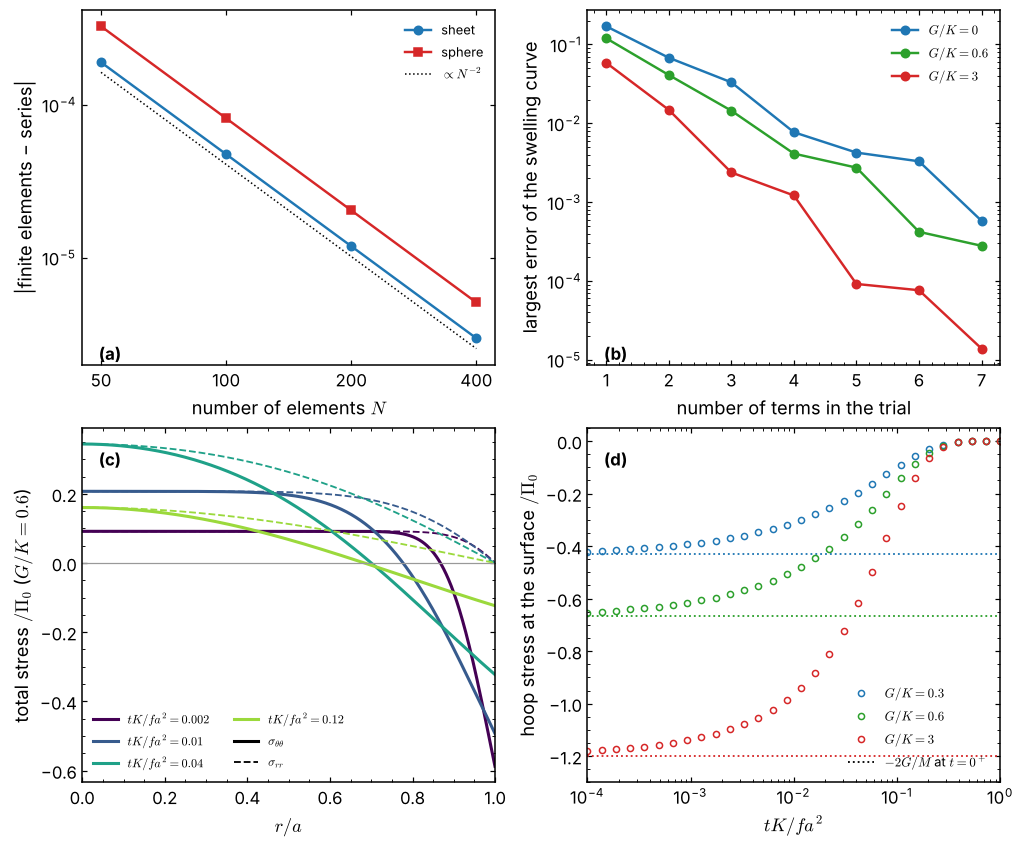

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(9.2, 7.6))
ax = axes[0, 0]
n_list = np.array([50, 100, 200, 400])
ax.loglog(n_list, [errors["sheet", n] for n in n_list], "C0o-", label="sheet")
ax.loglog(n_list, [errors["sphere", n] for n in n_list], "C3s-", label="sphere")
ax.loglog(n_list, 0.5 * errors["sphere", 50] * (n_list / 50.0) ** -2, "k:", lw=1, label=r"$\propto N^{-2}$")
ax.set_xticks(n_list, [str(n) for n in n_list]); ax.minorticks_off()
ax.set_xlabel("number of elements $N$"); ax.set_ylabel("|finite elements − series|")
ax.legend(loc="upper right", fontsize=8.5); on.panel_label(ax, "(a)", x=0.04, y=0.06)

ax = axes[0, 1]
for g, color in zip(exact_curves, ("C0", "C2", "C3")):
    ns = np.arange(1, 8)
    ax.semilogy(ns, [np.max(np.abs(ritz_swelling(n, g, t_fine) - exact_curves[g])) for n in ns], "o-", color=color, label=f"$G/K = {g:g}$")
ax.set_xlabel("number of terms in the trial"); ax.set_ylabel("largest error of the swelling curve")
ax.legend(loc="upper right", fontsize=8.5); on.panel_label(ax, "(b)", x=0.04, y=0.06)

ax = axes[1, 0]
for t, color in zip((0.002, 0.01, 0.04, 0.12), plt.cm.viridis(np.linspace(0, 0.85, 4))):
    xm, s_rr, s_tt = sphere_stresses(0.6, t)
    ax.plot(xm, s_tt, color=color, lw=2, label=f"$tK/fa^2 = {t:g}$")
    ax.plot(xm, s_rr, "--", color=color, lw=1.2)
ax.plot([], [], "k-", lw=2, label=r"$\sigma_{\theta\theta}$"); ax.plot([], [], "k--", lw=1.2, label=r"$\sigma_{rr}$")
ax.axhline(0, color="0.6", lw=0.8)
ax.set_xlabel("$r/a$"); ax.set_ylabel(r"total stress $/\Pi_0$ ($G/K = 0.6$)"); ax.set_xlim(0, 1)
ax.legend(loc="lower left", fontsize=8, ncol=2); on.panel_label(ax, "(c)", x=0.04, y=0.94)

ax = axes[1, 1]
ts = np.logspace(-4, 0, 30)
for g, color in zip((0.3, 0.6, 3.0), ("C0", "C2", "C3")):
    ax.semilogx(ts, surface_hoop_stress(g, ts), "o", color=color, mfc="none", ms=4, label=f"$G/K = {g:g}$")
    ax.axhline(-2 * g / (1 + 4 * g / 3), color=color, ls=":", lw=1.2)
ax.plot([], [], "k:", lw=1.2, label=r"$-2G/M$ at $t = 0^+$")
ax.set_xlabel(r"$tK/fa^2$"); ax.set_ylabel(r"hoop stress at the surface $/\Pi_0$"); ax.set_xlim(1e-4, 1); ax.set_ylim(-1.3, 0.05)
ax.legend(loc="lower right", fontsize=8.5); on.panel_label(ax, "(d)", x=0.04, y=0.94)
plt.show()

**Figure 11.3.** Checks. **(a)** Largest difference between the finite-element
solutions and the exact series (11.8) and (11.13), with $G/K = 0.6$: the error falls as
the square of the element size. **(b)** Convergence of the trial functions for the
sphere. **(c)** Total stresses $\boldsymbol\sigma - p\mathbf I$ inside a swelling sphere: hoop
(full lines) and radial (dashed). **(d)** The hoop stress at the surface, starting from
$-2G\Pi_0/M$ (dotted lines) and relaxing to zero.

The finite-element solutions agree with both series, and the error falls as $N^{-2}$,
to $5\times10^{-6}$ with 400 elements: the series (11.8) and the roots of Eq. (11.13) are
right. The trial functions converge more slowly for the swelling curve than for the
slowest rate. With three terms the rate is exact to four digits, but the curve is
still off by 0.01–0.03 at early times. Early on the swelling is confined to a thin
layer near the surface, as in Figure 11.1(b), and a few smooth polynomials cannot
represent a thin layer; the slowest mode, which governs the end of the swelling, is
smooth and easy to fit. The same was true of the diffusion trials of Chapter 5.

The stresses show what the diffusion equation alone hides. At the first instant the
surface layer swells in the radial direction but cannot expand sideways, because it
is attached to the core. It is therefore compressed in the hoop direction, by $2G\Pi_0/M$,
while the radial stress at the surface stays zero, as the boundary condition requires.
The core, which has not yet swollen, is pulled outwards by the swollen layer: it is
in tension, up to a third of $\Pi_0$ for $G/K = 0.6$. Both stresses relax as the swelling
reaches the centre. These are total stresses, $\boldsymbol\sigma - p\mathbf I$, the forces that the
gel transmits as a whole. The network stress (11.2) alone contains the swelling
pressure and is not what would crack the gel; at the surface, where $p = 0$, the two
are the same.

## 11.5 What to trust

* The theory is linear: it holds for small strains. A gel that swells to several
  times its volume needs the nonlinear free energy of Flory and Rehner, and the
  modulus and the friction then change with the swelling. The structure of the
  calculation, two functions and a minimum, stays the same.
* Equation (11.6) assumed that the volume flux vanishes. That is true for a sheet and
  a sphere, but not for a cylinder or a disk, where the solvent can flow along the
  axis while the network moves sideways. For those shapes the pressure must be
  kept, and Tanaka and Fillmore's equation fails (Li and Tanaka, 1990; Man and Doi,
  2021). The Rayleighian with the constraint (11.3) handles them without change.
* The compressive hoop stress at the surface, of order $G\Pi_0/M$, is what makes the
  surface of a swelling gel buckle into creases, a nonlinear instability outside this
  chapter.

## Summary

* A gel has the free energy of an elastic network driven by a swelling pressure, and
  the dissipation of solvent flowing through it. Minimising the Rayleighian gives
  force balance and Darcy's law; where the volume flux vanishes they combine into a
  diffusion equation for the network, $\dot{\mathbf u} = D\nabla(\nabla\cdot\mathbf u)$, $D = (K + \tfrac43G)/f$.
* A sheet bonded to a substrate swells, or is squeezed, in one direction, with the
  slowest time $4h^2/\pi^2D$. When squeezed, the load passes from the solvent to the
  network as the solvent drains out.
* A free sphere swells with a rate between $\pi^2K/fa^2$ and $15K/fa^2$: the bulk
  modulus sets the time, and the shear modulus changes it by at most a factor 1.5.
* A one-parameter trial, a uniform dilation, gives $15K/fa^2$ for any shear modulus;
  trial rates are upper bounds, and three terms give the exact rate to four digits.

## Exercises

Sample solutions are in [`solutions/part3_soft_materials/11_solutions.ipynb`](../../solutions/part3_soft_materials/11_solutions.ipynb).

1. **Times in practice.** A hydrogel has $D = 10^{-11}$ m²/s and $G/K = 0.6$. (a) How
   long does a sheet 0.5 mm thick, bonded to glass, take to reach 90 % of its final
   thickness? (b) How long does a free sphere of radius 0.5 mm take to reach 90 % of
   its final volume? (c) How long would Tanaka and Fillmore's formula (11.14) predict
   for the sphere, with this $D$?
2. **Squeezing.** A gel sheet of thickness $h$ on an impermeable base is squeezed by a
   porous piston with the pressure $P$. (a) Plot the solvent pressure at the base
   against time. (b) Show that the piston does the work $Ph\,\varepsilon_\infty$, where
   $\varepsilon_\infty = P/M$ is the final strain, and that half of it is stored in the
   network and half is dissipated; check this numerically from the dissipation
   $\int f\dot u^2\,dz\,dt$. (c) How much faster is the squeezing if the base is porous
   too?
3. **The sphere in detail.** (a) Show that the modes $u = j_1(\alpha r/a)$ satisfy
   Eq. (11.11), and that the condition (11.12) on the deviation from the final state
   gives Eq. (11.13). (b) Expand Eq. (11.13) for small $\alpha$ to show that
   $M\alpha_1^2 \to 15K$ as $G/K \to \infty$: the uniform dilation becomes exact.
4. **Reading a swelling experiment.** Experiments are often analysed by fitting
   Tanaka and Fillmore's curve (11.14) to the measured swelling, with $D$ as the free
   parameter. Fit it to the exact swelling curves of a sphere for $G/K$ from 0 to
   10. How does the fitted $D$ compare with the true $M/f$, and with $K/f$? What does a
   swelling experiment on a sphere actually measure?

## Suggested references

* M. Doi, *Soft Matter Physics* (Oxford University Press, 2013).
* M. Doi, "Gel dynamics", *J. Phys. Soc. Jpn.* **78**, 052001 (2009).
* T. Tanaka, L. O. Hocker and G. B. Benedek, "Spectrum of light scattered from a viscoelastic gel", *J. Chem. Phys.* **59**, 5151 (1973).
* T. Tanaka and D. J. Fillmore, "Kinetics of swelling of gels", *J. Chem. Phys.* **70**, 1214 (1979).
* A. Peters and S. J. Candau, "Kinetics of swelling of polyacrylamide gels", *Macromolecules* **19**, 1952 (1986).
* A. Peters and S. J. Candau, "Kinetics of swelling of spherical and cylindrical gels", *Macromolecules* **21**, 2278 (1988).
* Y. Li and T. Tanaka, "Kinetics of swelling and shrinking of gels", *J. Chem. Phys.* **92**, 1365 (1990).
* M. Doi and T. Yamaue, "Variational bounds for the relaxation times of swelling gels", *Phys. Rev. E* **71**, 041404 (2005).
* X. Man and M. Doi, "Swelling dynamics of a disk-shaped gel", *Macromolecules* **54**, 4626 (2021).
* M. A. Biot, "General theory of three-dimensional consolidation", *J. Appl. Phys.* **12**, 155 (1941).

---

**Previous:** [10. Diffusion and sedimentation of colloids](10_diffusion_sedimentation.ipynb) &nbsp;·&nbsp; **Next:** [12. Phase separation](12_phase_separation.ipynb)